# 01a · Exploración del dataset TBX11K

Este notebook es el punto de entrada del proyecto. Antes de entrenar cualquier modelo
necesito entender qué hay en el dataset: cómo están organizadas las imágenes, qué
etiquetas son utilizables, en qué formato vienen los archivos y si hay problemas de
calidad que puedan contaminar los experimentos posteriores.

**El notebook solo lee** `data/raw/TBX11K/`; no escribe ningún archivo.

Preguntas que guían la exploración:
- ¿Qué carpetas e imágenes tienen etiqueta utilizable para TB vs. no-TB?
- ¿Qué formato tienen las imágenes (tamaño, canales, profundidad de bits)?
- ¿Cómo se distribuyen las intensidades por clase y qué implica eso para la
  radiómica de primer orden?
- ¿Hay duplicados o anotaciones vacías que afecten el muestreo del subconjunto?

**Relación con el resto del proyecto**

```
01a (este notebook) ──► 01b (Montgomery-Shenzhen) ──► 02 (segmentación) ──► ...
```
TBX11K es el dataset objetivo: las 1600 imágenes de `subset.csv` son las que
terminarán pasando por los segmentadores y el extractor de características.
Montgomery-Shenzhen (01b) se usa solo para *entrenar* los segmentadores,
porque TBX11K no tiene máscaras pulmonares.

## 1 · Configuración del entorno

In [1]:
import hashlib
import json
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

# ── Rutas ──────────────────────────────────────────────────────────────────────
# Busco la raíz del proyecto subiendo desde el directorio actual. Así el notebook
# funciona tanto si lo ejecuto desde notebooks/ como desde la raíz.
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data" / "raw" / "TBX11K").exists()
)
DATA_DIR = ROOT / "data" / "raw" / "TBX11K"
IMG_DIR  = DATA_DIR / "imgs"
LIST_DIR = DATA_DIR / "lists"
ANNO_DIR = DATA_DIR / "annotations"

# ── Semilla ────────────────────────────────────────────────────────────────────
SEED = 42
rng  = np.random.default_rng(SEED)

# ── Clases con etiqueta pública ────────────────────────────────────────────────
# La etiqueta de cada imagen sale de la carpeta donde está guardada.
# Las carpetas test/ y extra/ no tienen etiqueta utilizable y se excluyen.
CLASSES       = {"tb": "TB", "health": "Sano", "sick": "Enfermo no-TB"}
CLASS_COLORS  = {"tb": "#2a78d6", "health": "#eb6834", "sick": "#1baf7a"}

# ── Estilo de figuras ──────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3",
    "axes.labelcolor": "#52514e",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#ecebe7",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 30)
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: d:\Documentos\GitHub\tuberculosis-lung-segmentation


## 2 · Estructura del dataset

### 2.1 Carpetas de imágenes

TBX11K organiza sus imágenes en cinco carpetas dentro de `imgs/`:

| Carpeta | Etiqueta | Uso en el proyecto |
|---------|----------|--------------------|
| `tb/`     | TB (activa + latente) | ✅ incluida |
| `health/` | Sano                  | ✅ incluida |
| `sick/`   | Enfermo no-TB         | ✅ incluida |
| `test/`   | Sin etiqueta          | ❌ excluida |
| `extra/`  | Otras fuentes (Montgomery, Shenzhen, DA/DB) | ❌ excluida |

Las listas `TBX11K_train.txt`, `TBX11K_val.txt` y `TBX11K_trainval.txt` dentro
de `lists/` definen la partición oficial de los autores.

### 2.2 Índice de imágenes etiquetadas

In [2]:
def read_list(name):
    """Lee un archivo de lista y devuelve un conjunto de rutas relativas."""
    return set((LIST_DIR / name).read_text().split())

# Cargo las tres listas oficiales
train_list, val_list, trainval_list = (
    read_list(f"TBX11K_{s}.txt") for s in ["train", "val", "trainval"]
)

# Construyo un índice con todas las imágenes de las tres carpetas etiquetadas.
# Cada fila tiene el identificador de la imagen, su ruta relativa, su clase y
# a qué partición oficial pertenece.
index = pd.DataFrame(
    [
        {"image_id": p.stem, "rel_path": f"{c}/{p.name}", "source_class": c}
        for c in CLASSES
        for p in sorted((IMG_DIR / c).glob("*.png"))
    ]
)
index["label"] = (index["source_class"] == "tb").astype(int)
index["official_split"] = np.where(
    index["rel_path"].isin(train_list), "train",
    np.where(index["rel_path"].isin(val_list), "val", "none")
)

print(f"Total de imágenes etiquetadas: {len(index)}")
print()
display(
    index.groupby(["source_class", "official_split"])
         .size()
         .rename("imágenes")
         .unstack(fill_value=0)
)

Total de imágenes etiquetadas: 8400



official_split,train,val
source_class,,
health,3000,800
sick,3000,800
tb,600,200


Las 8 400 imágenes de `tb/`, `health/` y `sick/` coinciden exactamente con `TBX11K_trainval.txt`. La partición oficial es aproximadamente 75 % train / 25 % val, estratificada por clase, lo que significa que cada fracción tiene la misma proporción de TB, sanas y enfermas no-TB.

El dato más relevante de esta tabla es el **desbalance entre clases**: hay 800 positivos (TB) frente a 7 600 negativos (sanas + enfermas no-TB), una proporción de 1:9,5. Este nivel de desbalance no es inusual en tamizaje de TB —la enfermedad tiene baja prevalencia incluso en poblaciones de riesgo— pero tiene consecuencias directas para el modelado:

- La **exactitud** (accuracy) deja de ser una métrica útil: un clasificador que siempre predice "no TB" tendría exactitud del 90 % sin aprender nada.
- Las métricas relevantes son **sensibilidad** (no dejar pasar casos reales de TB), **especificidad** y **AUC-ROC**, que son insensibles al desbalance.
- Si los clasificadores necesitan probabilidades calibradas, habrá que aplicar sobremuestreo (SMOTE u otro) o ajustar los pesos de clase. Eso se decide en el notebook de modelado, no aquí.

La partición oficial también servirá de referencia para comparar los resultados del proyecto con los reportados en el paper original de TBX11K.

### 2.3 Anotaciones de lesiones TB (cajas delimitadoras)

In [3]:
# Recorro todos los XML de anotaciones. Solo las imágenes TB tienen XML;
# las imágenes sanas y enfermas no-TB no vienen anotadas con cajas.
xml_rows, box_rows = [], []
for xml_path in sorted((ANNO_DIR / "xml").glob("*.xml")):
    root    = ET.parse(xml_path).getroot()
    objects = root.findall("object")
    xml_rows.append({
        "image_id":   xml_path.stem,
        "orig_width":  int(root.find("size/width").text),
        "orig_height": int(root.find("size/height").text),
        "n_boxes":     len(objects),
        # Concateno las categorías únicas de esta imagen, ordenadas
        "categories":  " + ".join(
            sorted({o.find("name").text for o in objects})
        ) or "(sin cajas)",
    })
    box_rows += [
        {"image_id": xml_path.stem, "category": o.find("name").text}
        for o in objects
    ]

xml_df = pd.DataFrame(xml_rows)
box_df = pd.DataFrame(box_rows)

# Verifico que haya exactamente un XML por imagen TB y ninguno de más.
tb_ids = set(index.loc[index["label"] == 1, "image_id"])
print("¿Un XML por cada imagen TB?:", set(xml_df["image_id"]) == tb_ids)
print()
print("Distribución de cajas por categoría:")
display(box_df["category"].value_counts().rename("cajas").to_frame())
print()
print("Combinaciones de categorías por imagen:")
display(xml_df["categories"].value_counts().rename("imágenes").to_frame())
print()
print("Cajas por imagen:")
display(
    xml_df["n_boxes"]
    .value_counts().sort_index()
    .rename("imágenes")
    .rename_axis("cajas por imagen")
    .to_frame()
)
print("Imágenes TB sin cajas:", xml_df.loc[xml_df["n_boxes"] == 0, "image_id"].tolist())

¿Un XML por cada imagen TB?: True

Distribución de cajas por categoría:


,cajas
category,
ActiveTuberculosis,972
ObsoletePulmonaryTuberculosis,239



Combinaciones de categorías por imagen:


,imágenes
categories,
ActiveTuberculosis,630
ObsoletePulmonaryTuberculosis,139
ActiveTuberculosis + ObsoletePulmonaryTuberculosis,30
(sin cajas),1



Cajas por imagen:


,imágenes
cajas por imagen,
0,1
1,417
2,355
3,24
4,3


Imágenes TB sin cajas: ['tb1199']


Las anotaciones revelan tres aspectos importantes de la clase TB:

**La clase TB no es homogénea.** Mezcla TB activa (`ActiveTuberculosis`) y TB latente u obsoleta (`ObsoletePulmonaryTuberculosis`). Clínicamente son distintas: la TB activa es infecciosa y tiene hallazgos radiológicos prominentes (consolidaciones, cavernas); la TB obsoleta deja secuelas fibróticas discretas que pueden ser difíciles de distinguir de otras patologías cicatriciales. Los 30 casos mixtos son pacientes en los que coexisten ambos tipos de lesión, probablemente TB activa sobre fondo de enfermedad antigua.

**El número de cajas por imagen varía ampliamente.** La mayoría de las imágenes tiene 1 o 2 cajas, pero algunas tienen 6 o más, lo que indica compromiso pulmonar extenso. Esta variabilidad no afecta la tarea de clasificación (la etiqueta es binaria), pero sí puede afectar las características radiómicas: una imagen con muchas lesiones tendrá valores muy distintos de textura y heterogeneidad dentro de la máscara pulmonar.

**`tb1199` no tiene cajas.** Puede ser un caso de TB extrapulmonar, TB miliar con patrón difuso difícil de delimitar con cajas, o un error de anotación. Su etiqueta sigue siendo TB, así que entra en el subconjunto de estudio. Vale la pena revisarla visualmente al hacer el control de calidad de las máscaras en el notebook 03.

Las anotaciones son **cajas de lesiones, no máscaras de pulmón**. No puedo usarlas directamente para entrenar los segmentadores; para eso necesito Montgomery-Shenzhen (notebook 01b).

## 3 · Exploración de imágenes

### 3.1 Formato y estadísticas de intensidad por imagen

In [4]:
# Recorro las 8 400 imágenes una sola vez. Por cada imagen registro:
#   - formato (forma, tipo, si los canales RGB son idénticos)
#   - estadísticas de intensidad (media, desviación, percentiles, fracción de negro/blanco)
#   - histograma de niveles de gris de 256 celdas
#   - hash MD5 del canal de grises (para detectar duplicados exactos)
# También acumulo la suma y la suma cuadrada de píxeles por clase,
# para calcular la imagen promedio y la desviación estándar espacial en 3.5.

stats_rows  = []
histograms  = np.zeros((len(index), 256), dtype=np.int64)
pix_sum     = {c: np.zeros((512, 512)) for c in CLASSES}
pix_sq      = {c: np.zeros((512, 512)) for c in CLASSES}

for i, row in enumerate(index.itertuples()):
    img = cv2.imread(str(IMG_DIR / row.rel_path), cv2.IMREAD_UNCHANGED)

    # Compruebo si los tres canales son idénticos (para saber si puedo leer
    # en escala de grises sin perder información)
    channels_equal = img.ndim == 2 or (
        np.array_equal(img[..., 0], img[..., 1]) and
        np.array_equal(img[..., 1], img[..., 2])
    )
    # Tomo el primer canal como imagen de grises (verificado arriba)
    gray = img if img.ndim == 2 else img[..., 0]

    histograms[i] = np.bincount(gray.ravel(), minlength=256)
    pix_sum[row.source_class] += gray
    pix_sq[row.source_class]  += gray.astype(np.float64) ** 2

    stats_rows.append({
        "shape":          img.shape,
        "dtype":          str(img.dtype),
        "channels_equal": channels_equal,
        "mean":           gray.mean(),
        "std":            gray.std(),
        "p01":            np.percentile(gray, 1),
        "p99":            np.percentile(gray, 99),
        "frac_black":     (gray == 0).mean(),
        "frac_white":     (gray == 255).mean(),
        "md5":            hashlib.md5(gray.tobytes()).hexdigest(),
    })

stats = pd.concat([index, pd.DataFrame(stats_rows)], axis=1)

print("Formas encontradas:", Counter(stats["shape"]))
print("Tipos de dato:",      Counter(stats["dtype"]))
print("¿Canales RGB idénticos en todas?:", stats["channels_equal"].all())

Formas encontradas: Counter({(512, 512, 3): 8400})
Tipos de dato: Counter({'uint8': 8400})
¿Canales RGB idénticos en todas?: True


Todas las imágenes miden 512 × 512 píxeles, son `uint8` y se guardaron en RGB con los **tres canales idénticos**. Puedo leerlas con `cv2.IMREAD_GRAYSCALE` sin perder información, lo que simplifica el pipeline y ahorra memoria.

Hay dos implicaciones menos obvias que vale la pena registrar:

**La resolución es fija pero artificial.** Los autores redimensionaron imágenes de tamaños originales distintos (distintos equipos de rayos X, distintas instituciones) a un cuadrado de 512 × 512. Eso distorsiona la relación de aspecto original y hace que el espaciado entre píxeles sea desconocido e inconsistente entre imágenes. Para la radiómica esto importa: las características de forma y textura que dependen de distancias reales (en mm) no se pueden calcular sin el espaciado. En la práctica usaré características adimensionales o normalizadas por el área de la máscara, y lo reportaré como limitación del dataset.

**`uint8` implica rango 0–255.** Algunos equipos de rayos X generan imágenes de 12 o 16 bits (4 096 o 65 536 niveles de gris). Al reducir a 8 bits se pierde gradación de intensidad, lo que puede afectar características de primer orden como la entropía o el rango dinámico. Este es un límite inherente de la versión pública del dataset, no algo que pueda corregirse en el preprocesado.

### 3.2 Ejemplos aleatorios por clase

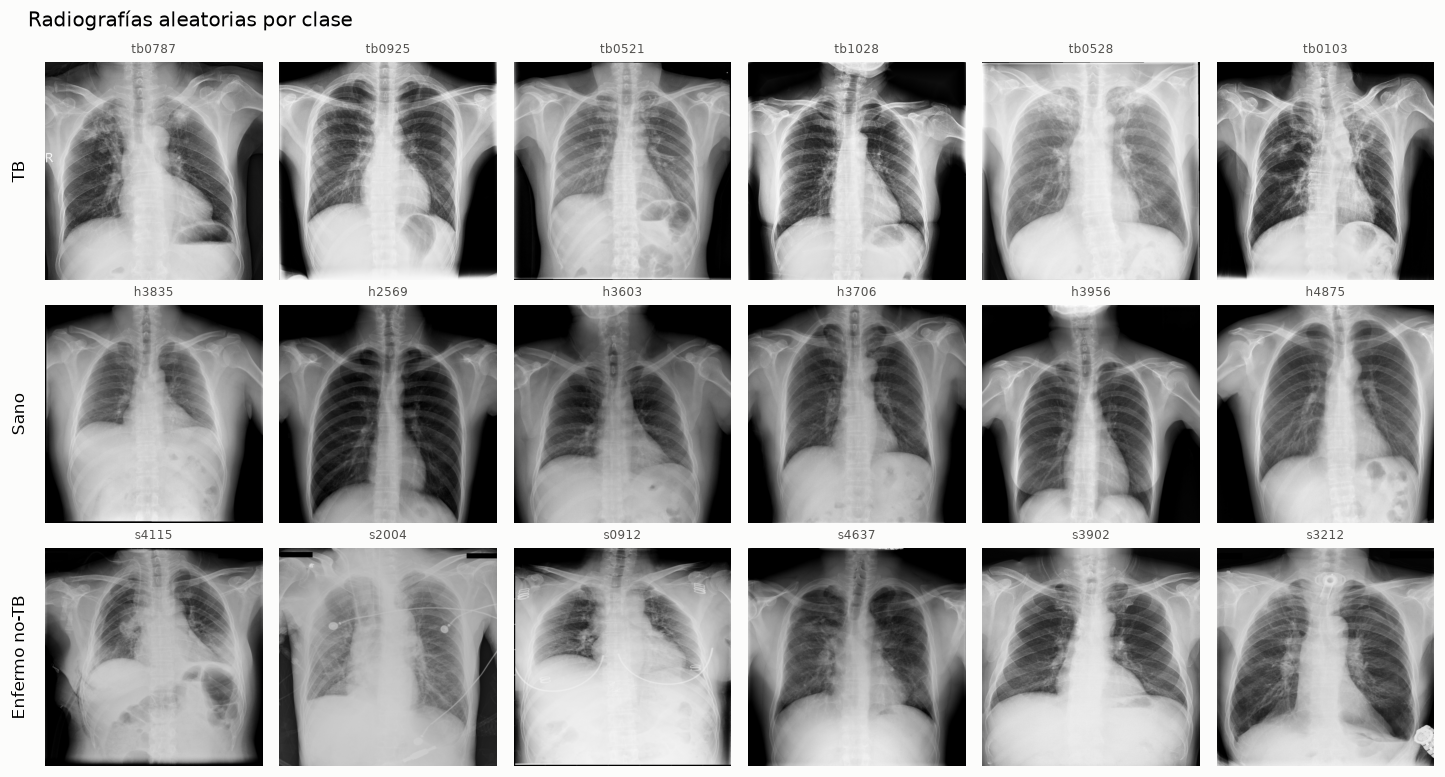

In [5]:
# Muestro 6 radiografías aleatorias de cada clase para tener una idea visual
# de cómo se ven antes de procesar nada.
n_cols = 6
fig, axes = plt.subplots(len(CLASSES), n_cols,
                          figsize=(2.2 * n_cols, 2.4 * len(CLASSES)))

for r, cls in enumerate(CLASSES):
    ids = rng.choice(
        index.loc[index["source_class"] == cls, "rel_path"], n_cols, replace=False
    )
    for c, rel in enumerate(ids):
        ax = axes[r, c]
        ax.imshow(
            cv2.imread(str(IMG_DIR / rel), cv2.IMREAD_GRAYSCALE),
            cmap="gray", vmin=0, vmax=255
        )
        ax.set_title(Path(rel).stem, fontsize=8, color="#52514e")
        ax.axis("off")
    axes[r, 0].text(
        -40, 256, CLASSES[cls], rotation=90, va="center", ha="right", fontsize=11
    )

fig.suptitle("Radiografías aleatorias por clase", x=0.02, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

### 3.3 Distribución espacial de las lesiones TB

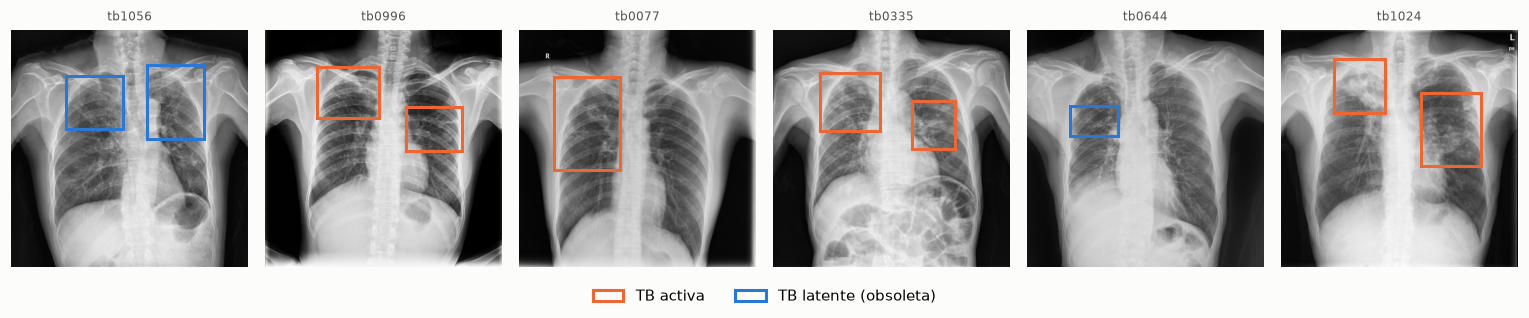

In [6]:
# Las cajas de lesión vienen en formato COCO (JSON), ya escaladas a 512×512.
# Las uso para ver dónde se ubican las lesiones dentro de la imagen.
coco      = json.loads((ANNO_DIR / "json" / "TBX11K_trainval_only_tb.json").read_text())
cat_names = {c["id"]: c["name"] for c in coco["categories"]}
img_files = {im["id"]: im["file_name"] for im in coco["images"]}

boxes_by_file = defaultdict(list)
for a in coco["annotations"]:
    boxes_by_file[img_files[a["image_id"]]].append(
        (a["bbox"], cat_names[a["category_id"]])
    )

# ── 6 ejemplos con sus cajas ──────────────────────────────────────────────────
BOX_COLORS = {
    "ActiveTuberculosis":         "#eb6834",
    "ObsoletePulmonaryTuberculosis": "#2a78d6",
}
sample = rng.choice(sorted(boxes_by_file), 6, replace=False)
fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
for ax, fname in zip(axes, sample):
    ax.imshow(
        cv2.imread(str(IMG_DIR / fname), cv2.IMREAD_GRAYSCALE),
        cmap="gray", vmin=0, vmax=255
    )
    for (x, y, w, h), cat in boxes_by_file[fname]:
        ax.add_patch(Rectangle((x, y), w, h, fill=False, lw=2, ec=BOX_COLORS[cat]))
    ax.set_title(Path(fname).stem, fontsize=8, color="#52514e")
    ax.axis("off")

handles = [Rectangle((0, 0), 1, 1, fill=False, lw=2, ec=col) for col in BOX_COLORS.values()]
fig.legend(handles, ["TB activa", "TB latente (obsoleta)"], loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

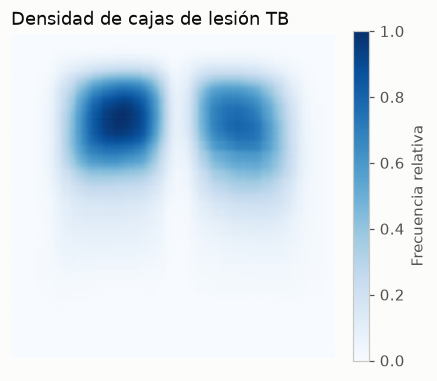

In [7]:
# Mapa de densidad de lesiones: acumulo cuántas cajas cubren cada píxel.
# El resultado muestra visualmente en qué zonas del pulmón se concentran las lesiones.
heat = np.zeros((512, 512))
for items in boxes_by_file.values():
    for (x, y, w, h), _ in items:
        heat[int(y):int(np.ceil(y + h)), int(x):int(np.ceil(x + w))] += 1

fig, ax = plt.subplots(figsize=(4.2, 4.2))
im = ax.imshow(heat / heat.max(), cmap="Blues", vmin=0, vmax=1)
ax.set_title("Densidad de cajas de lesión TB", loc="left")
ax.axis("off")
fig.colorbar(im, ax=ax, fraction=0.046, label="Frecuencia relativa")
plt.show()

El mapa confirma el patrón clásico de la TB pulmonar: las lesiones se concentran en los **lóbulos superiores**, especialmente en los segmentos apical y posterior. Este patrón tiene una explicación fisiológica bien establecida: los lóbulos superiores tienen mayor ventilación alveolar relativa y menor flujo linfático, lo que favorece la replicación del bacilo de Koch una vez que llega por vía aérea.

Hay dos observaciones adicionales que serán útiles más adelante:

**Asimetría izquierda-derecha.** La densidad es ligeramente mayor en el lado derecho, posiblemente porque el lóbulo superior derecho tiene tres segmentos (apical, posterior y anterior) frente a dos en el izquierdo (apical-posterior y anterior), y porque el bronquio derecho es más vertical, facilitando el depósito de partículas. Esta asimetría es consistente con la literatura clínica.

**Zona central vacía.** La franja vertical central del mapa tiene baja densidad de cajas porque corresponde al mediastino (corazón, grandes vasos, tráquea), que no forma parte del parénquima pulmonar. Que las cajas respeten esa zona indica que las anotaciones son clínicamente coherentes.

**Implicación para MedSAM:** las cajas-prompt que genere deben cubrir toda la silueta pulmonar, incluyendo los vértices superiores donde se concentran las lesiones. Un margen insuficiente en la zona apical haría que MedSAM recortara justo donde más información hay.

### 3.4 Distribución de intensidades por clase

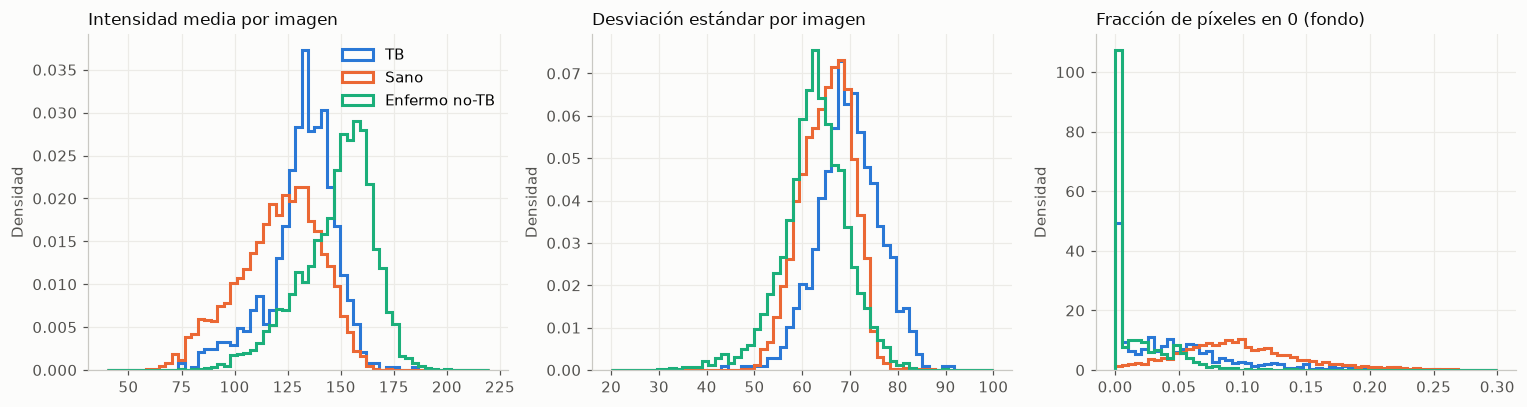

mean           std       frac_black      
                mean    std   mean   std       mean   std
source_class                                             
health        120.78  19.38  65.12  5.25       0.10  0.05
sick          148.04  17.22  62.56  6.89       0.02  0.02
tb            131.86  15.82  69.81  6.42       0.05  0.05

In [8]:
# Las características radiómicas de primer orden (media, percentiles, entropía…)
# dependen directamente de la distribución de intensidades dentro de la máscara.
# Si las clases ya difieren antes de segmentar, parte de la señal puede venir
# de diferencias de adquisición y no de la patología.

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
panels = [
    ("mean",       "Intensidad media por imagen",     np.linspace(40,  220, 60)),
    ("std",        "Desviación estándar por imagen",   np.linspace(20,  100, 60)),
    ("frac_black", "Fracción de píxeles en 0 (fondo)", np.linspace(0,   0.3, 60)),
]
for ax, (col, title, bins) in zip(axes, panels):
    for cls, name in CLASSES.items():
        ax.hist(
            stats.loc[stats["source_class"] == cls, col],
            bins=bins, density=True,
            histtype="step", lw=2, color=CLASS_COLORS[cls], label=name
        )
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylabel("Densidad")
axes[0].legend()
fig.tight_layout()
plt.show()

# Resumen numérico
display(
    stats.groupby("source_class")[["mean", "std", "frac_black"]]
         .agg(["mean", "std"])
         .round(2)
)

Las distribuciones muestran diferencias sistemáticas entre clases que merecen atención antes de llegar al modelado.

**Intensidad media.** Las imágenes sanas tienen la media más baja (≈ 121), las TB están en el medio (≈ 132) y las enfermas no-TB son las más brillantes (≈ 148). En radiografía de tórax, una mayor intensidad media suele indicar mayor radiopacidad: consolidaciones, derrames, fibrosis o masas que atenúan más los rayos X. El hecho de que `sick` sea la clase más brillante es consistente con que agrupa enfermedades respiratorias distintas de la TB, muchas de las cuales producen opacidades extensas.

**Fracción de fondo negro.** Las imágenes sanas tienen casi el 10 % de píxeles en valor 0 (fondo fuera de la silueta del paciente), mientras que en `sick` baja al 1,7 %. Esto ocurre porque en enfermedades graves el pulmón tiene menos aire y el borde pulmonar se acerca más al borde de la imagen, reduciendo el área de fondo. Es una señal espuria: no refleja la patología en sí, sino el campo visual de la radiografía.

**Riesgo de confusión sin segmentación.** Un clasificador entrenado sobre la imagen completa puede usar estas diferencias de intensidad global y de fondo para separar clases sin mirar el pulmón en absoluto. La segmentación corta ese atajo al restringir el análisis al interior del pulmón, donde la señal debería venir de la patología. Esta es una de las razones centrales por las que el proyecto compara distintos métodos de segmentación: si la máscara es mala (deja entrar fondo o pierde zonas del pulmón), el clasificador puede seguir aprendiendo señales espurias.

### 3.5 Imagen promedio y variabilidad espacial por clase

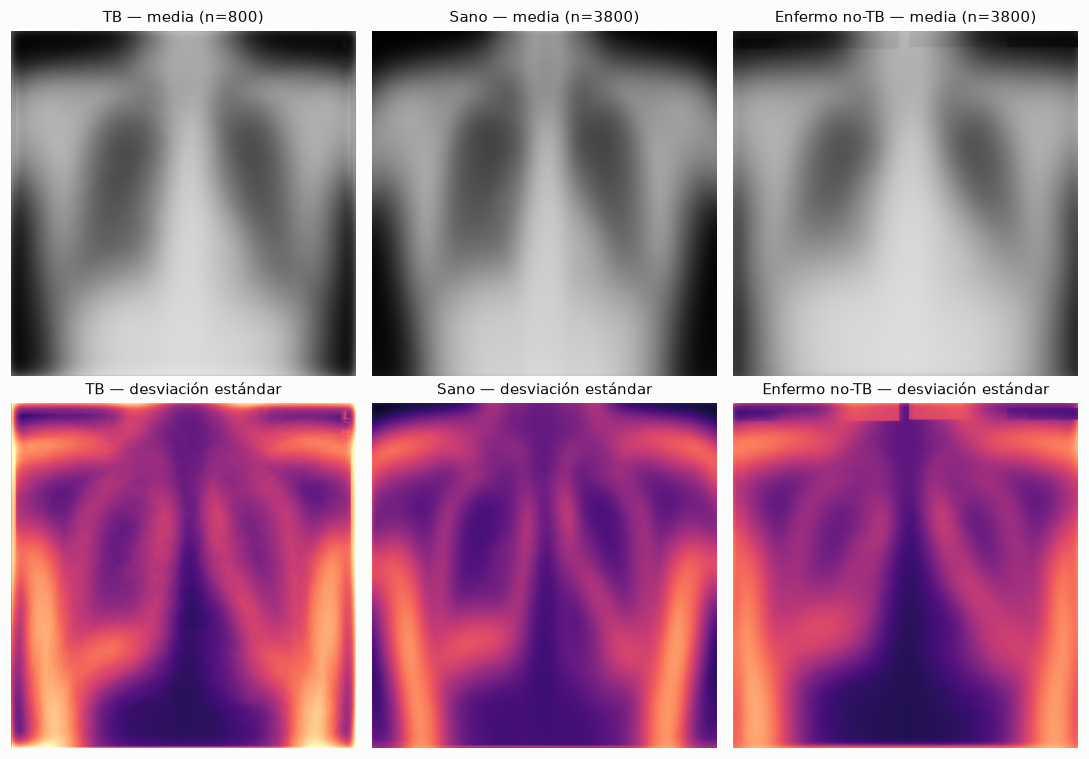

In [9]:
# La imagen promedio y el mapa de desviación estándar muestran, píxel a píxel,
# dónde cae típicamente el pulmón y cuánto varía su posición entre pacientes.
# Ambas imágenes se calculan con las sumas acumuladas en la sección 3.1,
# sin tener que releer ningún archivo.

fig, axes = plt.subplots(2, len(CLASSES), figsize=(10, 7))
for c, cls in enumerate(CLASSES):
    n        = (index["source_class"] == cls).sum()
    mean_img = pix_sum[cls] / n
    # Uso np.maximum para evitar valores negativos por errores de punto flotante
    std_img  = np.sqrt(np.maximum(pix_sq[cls] / n - mean_img ** 2, 0))

    axes[0, c].imshow(mean_img, cmap="gray", vmin=0, vmax=255)
    axes[0, c].set_title(f"{CLASSES[cls]} — media (n={n})", fontsize=10)
    axes[1, c].imshow(std_img, cmap="magma", vmin=0, vmax=90)
    axes[1, c].set_title(f"{CLASSES[cls]} — desviación estándar", fontsize=10)

for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
plt.show()

Las imágenes promedio muestran que el dataset está bien centrado: el pulmón cae sistemáticamente en la misma región de la imagen en las tres clases. Esto es consecuencia del redimensionado a 512 × 512 aplicado por los autores, que alinea implícitamente las siluetas.

Los mapas de desviación estándar son más informativos:

**Las zonas de alta varianza coinciden con los bordes pulmonares y el mediastino.** Ahí es donde la posición del corazón, el diafragma y las cúpulas pleurales varía entre pacientes. Un segmentador que falle en esas zonas cometerá errores sistemáticos precisamente en las regiones más variables, lo que se traducirá en máscaras inconsistentes entre imágenes.

**La varianza en los ápices es alta en TB.** Comparada con las otras dos clases, la clase TB tiene más varianza en los campos superiores, coherente con la presencia de lesiones heterogéneas (cavernas, consolidaciones, fibrosis) que alteran la densidad local. Este es un indicio de que las características de textura extraídas en esa zona deberían tener poder discriminativo.

**Implicación para el análisis de características.** En el notebook 03 calcularé las características radiómicas con distintas máscaras. Si la desviación estándar espacial cambia mucho entre métodos de segmentación en las zonas de alta varianza (bordes, ápices), esperaría que las características de forma y textura sean las más sensibles al método elegido.

### 3.6 Detección de duplicados exactos

In [10]:
# Agrupo por hash MD5 del canal de grises. Si dos imágenes tienen el mismo hash
# son idénticas píxel a píxel, aunque los metadatos del PNG difieran.
dup_groups = [
    g["image_id"].tolist()
    for _, g in stats.groupby("md5")
    if len(g) > 1
]
dup_df = pd.DataFrame({"grupo": range(len(dup_groups)), "image_ids": dup_groups})

# Anoto qué clase(s) aparecen en cada grupo de duplicados
id_to_class = index.set_index("image_id")["source_class"]
dup_df["clases"] = dup_df["image_ids"].map(
    lambda ids: " + ".join(sorted({id_to_class[i] for i in ids}))
)

print("Grupos de imágenes idénticas (píxel a píxel):", len(dup_groups))
display(dup_df["clases"].value_counts().rename("grupos").to_frame())
display(dup_df.head(10))

# Cuántos duplicados caen en particiones oficiales distintas (fuga de datos)
split_by_id = index.set_index("image_id")["official_split"]
cross = sum(
    len({split_by_id[i] for i in ids}) > 1
    for ids in dup_groups
)
print(f"Grupos repartidos entre train y val oficiales: {cross}")

Grupos de imágenes idénticas (píxel a píxel): 126


,grupos
clases,
sick,126


,grupo,image_ids,clases
0,0,"[s2669, s4818]",sick
1,1,"[s1433, s1983]",sick
2,2,"[s1463, s2801]",sick
3,3,"[s4125, s4217]",sick
4,4,"[s3503, s4248]",sick
5,5,"[s0583, s3878]",sick
6,6,"[s1004, s2904]",sick
7,7,"[s0647, s4415]",sick
8,8,"[s0199, s2193]",sick
9,9,"[s4402, s4862]",sick


Grupos repartidos entre train y val oficiales: 38


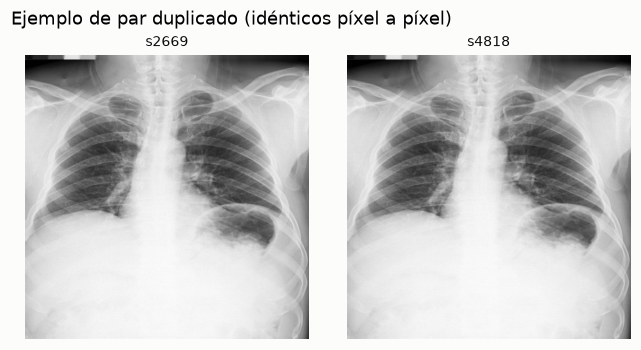

In [11]:
# Visualizo un par duplicado para confirmar que son idénticas y no solo similares
a, b = dup_groups[0]
fig, axes = plt.subplots(1, 2, figsize=(6, 3.2))
for ax, image_id in zip(axes, (a, b)):
    rel = index.set_index("image_id").loc[image_id, "rel_path"]
    ax.imshow(cv2.imread(str(IMG_DIR / rel), cv2.IMREAD_GRAYSCALE), cmap="gray")
    ax.set_title(image_id, fontsize=9)
    ax.axis("off")
fig.suptitle("Ejemplo de par duplicado (idénticos píxel a píxel)", x=0.02, ha="left")
fig.tight_layout()
plt.show()

Hay **126 pares de imágenes idénticas píxel a píxel, todos dentro de la clase `sick`**. Ninguno cruza clases, lo que descarta que haya imágenes sanas o TB duplicadas con distinta etiqueta (un error de anotación más grave).

**¿Por qué hay duplicados en `sick`?** Una causa probable es que la clase agrupa imágenes de varias fuentes externas y el proceso de recolección introdujo copias sin detectarlas. El hecho de que los duplicados sean exactos (mismo hash MD5) descarta que sean imágenes parecidas del mismo paciente en distintas fechas; son literalmente el mismo archivo.

**El problema real son los 38 pares que caen en train y val a la vez.** Si se entrena con esos duplicados, el modelo evalúa sobre imágenes que ya vio, lo que infla artificialmente las métricas de validación. Es una forma silenciosa de fuga de datos: no hay ninguna advertencia en el dataset original.

**La solución que aplico** es eliminar duplicados por hash antes de muestrear las 400 imágenes de `sick` para `subset.csv`. El módulo `tbseg.data` ya lo hace: de cada grupo de duplicados conserva solo la primera imagen por orden alfabético y descarta las demás. El archivo `subset.csv` resultante está versionado en el repositorio, así que todos los experimentos parten exactamente del mismo conjunto de imágenes.

## 4 · Conclusiones e implicaciones para el proyecto

Esta exploración establece las condiciones de partida del dataset y las decisiones de diseño que se propagan a todos los notebooks siguientes.

### Lo que tiene el dataset

- **8 400 imágenes con etiqueta**: 800 TB, 3 800 sanas y 3 800 enfermas no-TB.   Las carpetas `test/` y `extra/` no tienen etiqueta pública y quedan fuera.
- **Desbalance 1:9,5** entre TB y no-TB. La métrica principal de los clasificadores   será AUC-ROC, no exactitud.
- **Anotaciones de lesiones TB** en formato XML y COCO (cajas delimitadoras),   no máscaras de pulmón. La clase TB mezcla TB activa y latente; 30 imágenes   tienen cajas de ambos tipos. Un caso (`tb1199`) no tiene cajas y merece   revisión visual en el notebook 03.

### Lo que le falta al dataset (limitaciones)

- **Sin máscaras pulmonares**: necesito entrenar los segmentadores en   Montgomery-Shenzhen y aplicarlos aquí.
- **Sin espaciado físico**: las imágenes están redimensionadas a 512 × 512 sin   conservar la relación de aspecto ni el espaciado original en mm. Las   características radiómicas dependientes de distancias reales no son comparables   entre imágenes.
- **Reducción a 8 bits**: se pierde gradación de intensidad respecto a las   imágenes originales de 12–16 bits.

### Decisiones de diseño 

| Decisión | Justificación |
|----------|---------------|
| Leer con `cv2.IMREAD_GRAYSCALE` | Los tres canales RGB son idénticos |
| Eliminar duplicados por hash MD5 antes de muestrear `sick` | 38 pares cruzan train/val oficial: fuga de datos |
| Usar AUC-ROC como métrica principal | Desbalance 1:9,5 hace inutilizable la exactitud |
| Usar solo características adimensionales o normalizadas por área | Sin espaciado físico no puedo calcular distancias reales en mm |

